# Titanic Survival Analysis (Pandas + NumPy)

**Goal:** Ye samajhna ki Titanic jahaz par kin logon ke bachne ke chances zyada the, aur kyun.

**Steps:**
1. Data load karna aur pehli nazar
2. Data cleaning (missing values)
3. NumPy se basic calculations
4. Pandas groupby se analysis
5. Charts
6. Findings

**Dataset:** Titanic (seaborn library ke saath aata hai, 891 passengers)

## 1. Libraries import aur data load

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Pehli nazar: data kaisa dikhta hai?

In [2]:
print("Rows, Columns:", df.shape)
df.info()

Rows, Columns: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [3]:
# numeric columns ka summary
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 3. Data Cleaning

Pehle dekhte hain kis column mein kitni values missing hain.

In [4]:
missing = df.isna().sum()
missing_percent = (missing / len(df) * 100).round(1)

pd.DataFrame({"missing": missing, "percent": missing_percent}).query("missing > 0")

,missing,percent
age,177,19.9
embarked,2,0.2
deck,688,77.2
embark_town,2,0.2


**Faisle (decisions):**
- `deck`: ~77% missing hai, isliye is column ko **drop** karenge.
- `age`: 177 missing hai. Average kharab ho sakta hai outliers ki wajah se, isliye **median** se bharenge.
- `embarked` / `embark_town`: sirf 2 missing, **mode** (sabse common value) se bharenge.

In [5]:
df_clean = df.copy()

# 1. deck column hatao
df_clean = df_clean.drop(columns=["deck"])

# 2. age ko median se bharo
median_age = df_clean["age"].median()
df_clean["age"] = df_clean["age"].fillna(median_age)

# 3. embarked aur embark_town ko mode se bharo
df_clean["embarked"] = df_clean["embarked"].fillna(df_clean["embarked"].mode()[0])
df_clean["embark_town"] = df_clean["embark_town"].fillna(df_clean["embark_town"].mode()[0])

print("Median age jo use hui:", median_age)
print("Ab total missing values:", df_clean.isna().sum().sum())

Median age jo use hui: 28.0
Ab total missing values: 0


**Duplicates ka check:** Is dataset mein koi passenger ID column nahi hai, isliye same values wali rows asli duplicates nahi, alag passengers ho sakte hain. Isliye inhe drop **nahi** karenge.

In [6]:
print("Bilkul same rows:", df_clean.duplicated().sum())

Bilkul same rows: 116


## 4. NumPy se calculations

NumPy ka use karke `fare` (kiraya) ko samajhte hain.

In [7]:
fare = df_clean["fare"].to_numpy()

print("Mean fare  :", round(np.mean(fare), 2))
print("Median fare:", round(np.median(fare), 2))
print("Std dev    :", round(np.std(fare), 2))

# outliers: Q1, Q3 aur IQR method
q1, q3 = np.percentile(fare, [25, 75])
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr
print("Fare outliers ki upper limit:", round(upper_limit, 2))
print("Outliers ki ginti:", np.sum(fare > upper_limit))

Mean fare  : 32.2
Median fare: 14.45
Std dev    : 49.67
Fare outliers ki upper limit: 65.63
Outliers ki ginti: 116


Mean median se kaafi zyada hai, matlab kuch bahut mehngi tickets hain jo average ko upar kheench rahi hain. Isliye is data mein **median** zyada bharosemand hai.

**np.where se nayi column banate hain:** `age_group`
(Bacche, Teen, Young Adult, Adult, Senior)

In [8]:
age = df_clean["age"].to_numpy()

df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Young Adult", "Adult", "Senior"],
)

# np.where se ek simple flag: akela tha ya family ke saath
df_clean["travel_type"] = np.where(df_clean["alone"], "Alone", "With family")

df_clean[["age", "age_group", "alone", "travel_type"]].head()

,age,age_group,alone,travel_type
0,22.0,Young Adult,False,With family
1,38.0,Adult,False,With family
2,26.0,Young Adult,True,Alone
3,35.0,Young Adult,False,With family
4,35.0,Young Adult,True,Alone


## 5. Analysis: Pandas groupby

In [9]:
overall = df_clean["survived"].mean()
print(f"Total survival rate: {overall:.1%}")

Total survival rate: 38.4%


### Gender ke hisaab se

In [10]:
df_clean.groupby("sex")["survived"].mean().round(3)

sex
female    0.742
male      0.189
Name: survived, dtype: float64

### Ticket class ke hisaab se

In [11]:
df_clean.groupby("pclass")["survived"].mean().round(3)

pclass
1    0.630
2    0.473
3    0.242
Name: survived, dtype: float64

### Age group ke hisaab se

In [12]:
df_clean.groupby("age_group", observed=True)["survived"].agg(["mean", "count"]).round(3)

,mean,count
age_group,,
Child,0.580,69
Teen,0.429,70
Young Adult,0.353,535
Adult,0.400,195
Senior,0.227,22


### Class aur gender saath mein

In [13]:
pd.pivot_table(df_clean, values="survived", index="pclass", columns="sex", aggfunc="mean").round(3)

sex,female,male
pclass,,
1,0.968,0.369
2,0.921,0.157
3,0.500,0.135


### Akela vs family ke saath

In [14]:
df_clean.groupby("travel_type")["survived"].mean().round(3)

travel_type
Alone          0.304
With family    0.506
Name: survived, dtype: float64

## 6. Charts

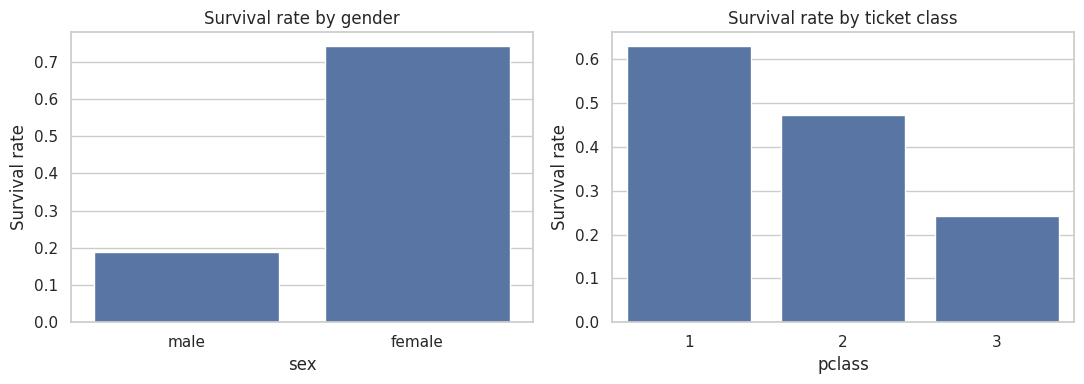

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.barplot(data=df_clean, x="sex", y="survived", ax=axes[0], errorbar=None)
axes[0].set_title("Survival rate by gender")
axes[0].set_ylabel("Survival rate")

sns.barplot(data=df_clean, x="pclass", y="survived", ax=axes[1], errorbar=None)
axes[1].set_title("Survival rate by ticket class")
axes[1].set_ylabel("Survival rate")

plt.tight_layout()
plt.show()

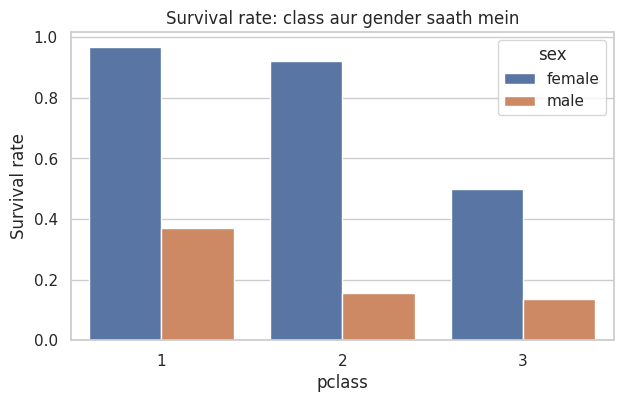

In [16]:
plt.figure(figsize=(7, 4))
sns.barplot(data=df_clean, x="pclass", y="survived", hue="sex", errorbar=None)
plt.title("Survival rate: class aur gender saath mein")
plt.ylabel("Survival rate")
plt.show()

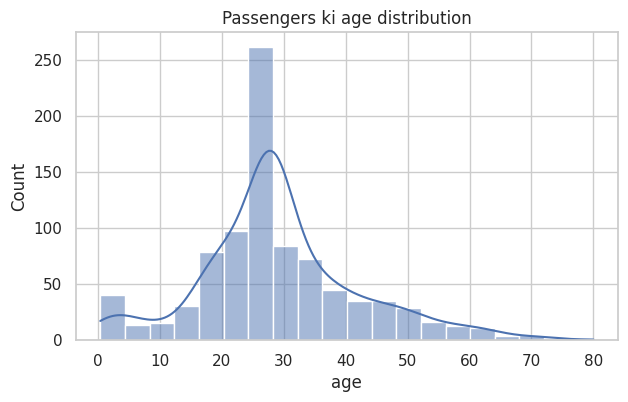

In [17]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df_clean, x="age", bins=20, kde=True)
plt.title("Passengers ki age distribution")
plt.show()

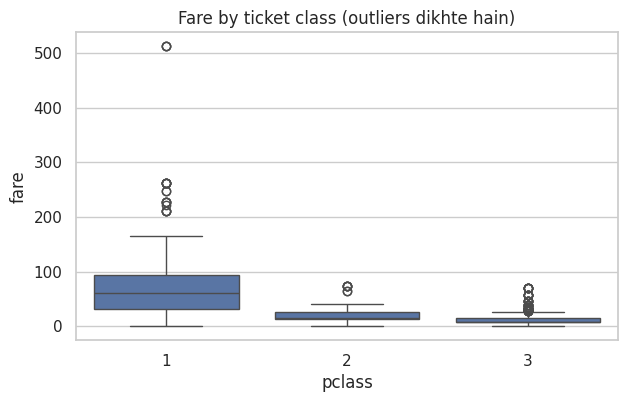

In [18]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_clean, x="pclass", y="fare")
plt.title("Fare by ticket class (outliers dikhte hain)")
plt.show()

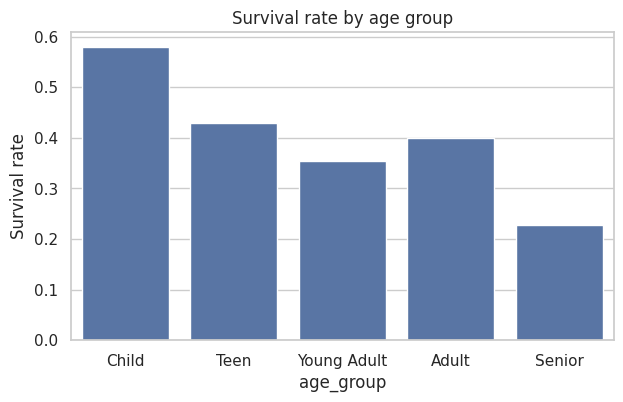

In [19]:
plt.figure(figsize=(7, 4))
order = ["Child", "Teen", "Young Adult", "Adult", "Senior"]
sns.barplot(data=df_clean, x="age_group", y="survived", order=order, errorbar=None)
plt.title("Survival rate by age group")
plt.ylabel("Survival rate")
plt.show()

## 7. Findings

1. **Gender sabse bada factor tha:** mahilaon ki survival rate lagbhag **74%** thi, jabki purushon ki sirf **19%**.
2. **Class ne bhi bahut farak dala:** 1st class mein **63%** bache, 2nd mein **47%**, aur 3rd class mein sirf **24%**.
3. **Dono ka combination:** 1st class ki mahilaon mein **97%** bachi, jabki 3rd class ke purushon mein sirf **13.5%**.
4. **Bacchon ko priority mili:** 12 saal se chhote bacchon ki survival rate **58%** thi, jabki 60+ age wale logon ki sirf **23%**.
5. **Akele yatri kam bache:** akele travel karne wale **30%** bache, family ke saath wale **51%**.
6. **Fare data skewed hai:** 1st class ka median fare 60.29 hai jabki 3rd class ka 8.05, aur kuch bahut mehngi tickets mean ko upar kheenchti hain.

## Limitations

- Ye sirf ek observation hai, isse **causation** (kaaran) prove nahi hota. Sirf pattern dikhta hai.
- Age ki 177 values median se bhari gayi hain, isliye age-based results thode approximate hain.
- Dataset chhota hai (891 rows).

## Aage kya ho sakta hai

- Family size aur survival ka relation dekhna
- Ek simple Logistic Regression model banana